## Imports, Data Loading & Overview

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
data_path = Path("../data/mini_project_1_data.csv")
if not data_path.exists():
    data_path = Path("../data/mini_project_1_data.xlsx")

df = pd.read_csv(data_path) if data_path.suffix.lower() == ".csv" else pd.read_excel(data_path)
df.columns = [c.strip() for c in df.columns]

mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"Loaded: {data_path.name} | Shape: {df.shape} | Memory: {mem_mb:.2f} MB")
display(df.head())
display(df.sample(5, random_state=42))
display(df.info())


Loaded: mini_project_1_data.csv | Shape: (35680, 30) | Memory: 15.51 MB


,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,...,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
0,0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,monday,593,12.0,219.0,0.663594,1.0,0.815385,...,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,monday,711,9.0,255.0,0.604743,1.0,0.791946,...,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,monday,1500,9.0,211.0,0.575130,1.0,0.663866,...,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,monday,1200,9.0,531.0,0.503788,1.0,0.665635,...,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,monday,505,13.0,1072.0,0.415646,1.0,0.540890,...,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,...,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
3799,4215,http://mashable.com/2013/03/22/embracing-kids-...,657.0,friday,2900,10.0,873.0,0.431193,1.0,0.668132,...,9.0,217.0,859.0,522.750000,0.0,617900.0,86317.666667,0.000000,3228.843445,2194.127674
23435,26047,http://mashable.com/2014/05/29/pocket-goes-pre...,224.0,thursday,1700,9.0,344.0,0.568047,1.0,0.703704,...,9.0,-1.0,613.0,154.500000,0.0,843300.0,264733.333333,0.000000,3578.303885,2298.906901
28419,31605,http://mashable.com/2014/08/27/lmfao-singer-gl...,134.0,wednesday,1200,10.0,283.0,0.535461,1.0,0.625000,...,7.0,-1.0,58.0,7.428571,44800.0,843300.0,452542.857143,1975.446856,3860.024210,3050.249019
14617,16216,http://mashable.com/2013/11/16/tom-hiddleston-...,418.0,saturday,12300,6.0,914.0,0.472379,1.0,0.672253,...,5.0,4.0,1300.0,316.200000,9700.0,843300.0,222000.000000,2779.106223,4102.087743,3307.430510
34915,38797,http://mashable.com/2014/12/12/christmas-jumpe...,24.0,monday,1800,16.0,0.0,0.000000,0.0,0.000000,...,10.0,-1.0,581.0,125.000000,0.0,843300.0,300610.000000,0.000000,9749.595238,4494.589648


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35680 entries, 0 to 35679
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         35680 non-null  int64  
 1   URL                        35680 non-null  object 
 2   timedelta                  35680 non-null  float64
 3   weekday                    35680 non-null  object 
 4   shares                     35680 non-null  int64  
 5   n_tokens_title             35680 non-null  float64
 6   n_tokens_content           35680 non-null  float64
 7   n_unique_tokens            35680 non-null  float64
 8   n_non_stop_words           35680 non-null  float64
 9   n_non_stop_unique_tokens   35680 non-null  float64
 10  num_hrefs                  34959 non-null  float64
 11  num_self_hrefs             34959 non-null  float64
 12  num_imgs                   34261 non-null  float64
 13  num_videos                 18925 non-null  flo

None

## Duplicate, Missing Value & Sentinel -1 Audit

In [3]:
print(f"Duplicate URLs: {df['URL'].duplicated().sum()}")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing_Count": missing, "Missing_Pct (%)": missing_pct})
display(missing_df[missing_df["Missing_Count"] > 0].sort_values(by="Missing_Count", ascending=False))

# Check -1 sentinel counts in keyword columns
kw_cols = [c for c in df.columns if c.startswith("kw_")]
neg_counts = {c: int((df[c] < 0).sum()) for c in kw_cols if (df[c] < 0).sum() > 0}
print("Sentinel (< 0) value counts in keyword features:", neg_counts)


Duplicate URLs: 0


,Missing_Count,Missing_Pct (%)
num_videos,16755,46.96
data_channel,5462,15.31
num_imgs,1419,3.98
num_hrefs,721,2.02
num_self_hrefs,721,2.02
self_reference_min_shares,721,2.02
self_reference_max_shares,721,2.02
self_reference_avg_shares,721,2.02


Sentinel (< 0) value counts in keyword features: {'kw_min_min': 20660, 'kw_avg_min': 767, 'kw_min_avg': 6}


## Data Cleaning & Feature Engineering

In [4]:
initial_rows = len(df)
df_clean = df.drop_duplicates(subset=["URL"], keep="first").copy()

df_clean["weekday"] = df_clean["weekday"].astype(str).str.strip().str.lower()
df_clean["data_channel"] = df_clean["data_channel"].fillna("unknown").astype(str).str.strip().str.lower()

num_cols = [c for c in df_clean.select_dtypes(include=[np.number]).columns if c not in {"ID", "shares", "timedelta"}]
for col in num_cols:
    if col in {"n_unique_tokens", "n_non_stop_words", "n_non_stop_unique_tokens"}:
        df_clean.loc[(df_clean[col] < 0) | (df_clean[col] > 1), col] = np.nan
    else:
        df_clean.loc[df_clean[col] < 0, col] = np.nan

df_clean["total_media"] = df_clean["num_imgs"].fillna(0) + df_clean["num_videos"].fillna(0)
df_clean["is_weekend"] = df_clean["weekday"].isin(["saturday", "sunday"]).astype(int)
df_clean["kw_avg_range"] = df_clean["kw_max_avg"] - df_clean["kw_min_avg"]

print(f"Rows before deduplication: {initial_rows} | After: {len(df_clean)}")
display(df_clean[["shares", "n_tokens_content", "num_hrefs", "num_imgs", "num_videos", "kw_avg_avg"]].describe().T)


Rows before deduplication: 35680 | After: 35680


,count,mean,std,min,25%,50%,75%,max
shares,35680.0,3402.054961,11934.878541,4.0,946.00000,1400.000000,2800.000000,843300.000000
n_tokens_content,35680.0,545.995123,469.550052,0.0,247.00000,410.000000,716.000000,8474.000000
num_hrefs,34959.0,10.866358,11.260971,0.0,4.00000,8.000000,14.000000,304.000000
num_imgs,34261.0,4.513003,8.259735,0.0,1.00000,1.000000,4.000000,128.000000
num_videos,18925.0,1.286446,4.148189,0.0,0.00000,0.000000,1.000000,91.000000
kw_avg_avg,35680.0,3130.799667,1311.012948,0.0,2379.76229,2867.991456,3595.530145,43567.659946


## Target Distribution (shares vs. log1p(shares))

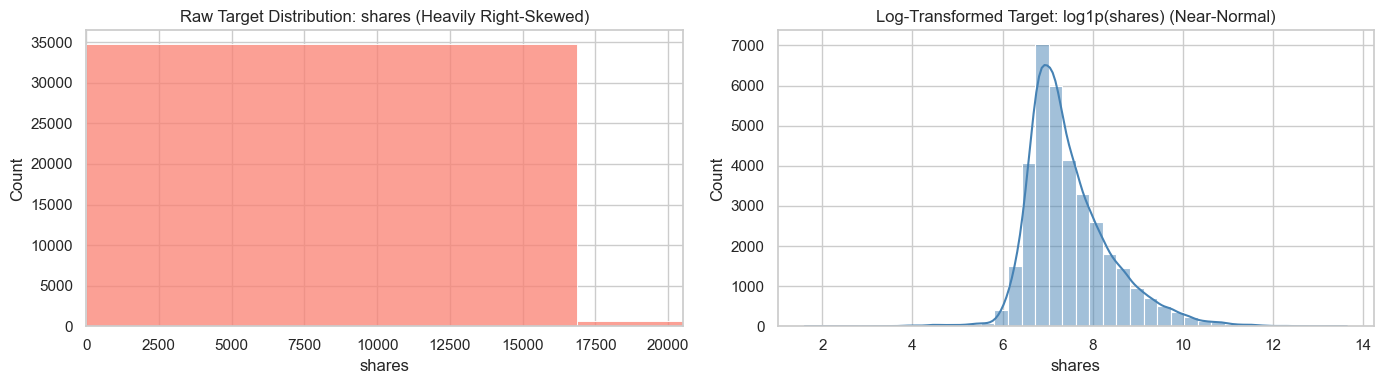

Skewness (raw shares): 34.41 | Skewness (log1p): 1.04


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_clean["shares"], bins=50, ax=ax1, color="salmon")
ax1.set_title("Raw Target Distribution: shares (Heavily Right-Skewed)")
ax1.set_xlim(0, df_clean["shares"].quantile(0.98))

sns.histplot(np.log1p(df_clean["shares"]), bins=40, kde=True, ax=ax2, color="steelblue")
ax2.set_title("Log-Transformed Target: log1p(shares) (Near-Normal)")
plt.tight_layout()
plt.show()

print(f"Skewness (raw shares): {df_clean['shares'].skew():.2f} | Skewness (log1p): {np.log1p(df_clean['shares']).skew():.2f}")


## Dedicated IQR Outlier Audit Across Key Predictors

In [6]:
audit_cols = ["shares", "n_tokens_content", "num_hrefs", "num_imgs", "num_videos", "n_comments", "self_reference_avg_shares", "kw_avg_avg"]
records = []
for col in audit_cols:
    s = df_clean[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < low) | (s > high)).sum())
    records.append({
        "Feature": col, "Q1": round(q1, 2), "Q3": round(q3, 2), "IQR": round(iqr, 2),
        "Upper_Bound": round(high, 2), "Outlier_Count": n_out, "Outlier_Pct (%)": round(n_out / len(s) * 100, 2)
    })
display(pd.DataFrame(records).sort_values(by="Outlier_Pct (%)", ascending=False))


,Feature,Q1,Q3,IQR,Upper_Bound,Outlier_Count,Outlier_Pct (%)
3,num_imgs,1.00,4.00,3.00,8.50,6614,19.30
0,shares,946.00,2800.00,1854.00,5581.00,4080,11.43
6,self_reference_avg_shares,978.00,5166.67,4188.67,11449.67,3728,10.66
5,n_comments,2.00,78.00,76.00,192.00,3461,9.70
4,num_videos,0.00,1.00,1.00,2.50,1464,7.74
2,num_hrefs,4.00,14.00,10.00,29.00,1899,5.43
1,n_tokens_content,247.00,716.00,469.00,1419.50,1705,4.78
7,kw_avg_avg,2379.76,3595.53,1215.77,5419.18,1466,4.11


## Bivariate Popularity by data_channel and weekday

C:\Users\Ram\AppData\Local\Temp\ipykernel_29524\2536416658.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="data_channel", y="log_shares", ax=ax1, palette="Set2")
C:\Users\Ram\AppData\Local\Temp\ipykernel_29524\2536416658.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="weekday", y="log_shares", order=day_order, ax=ax2, palette="coolwarm")


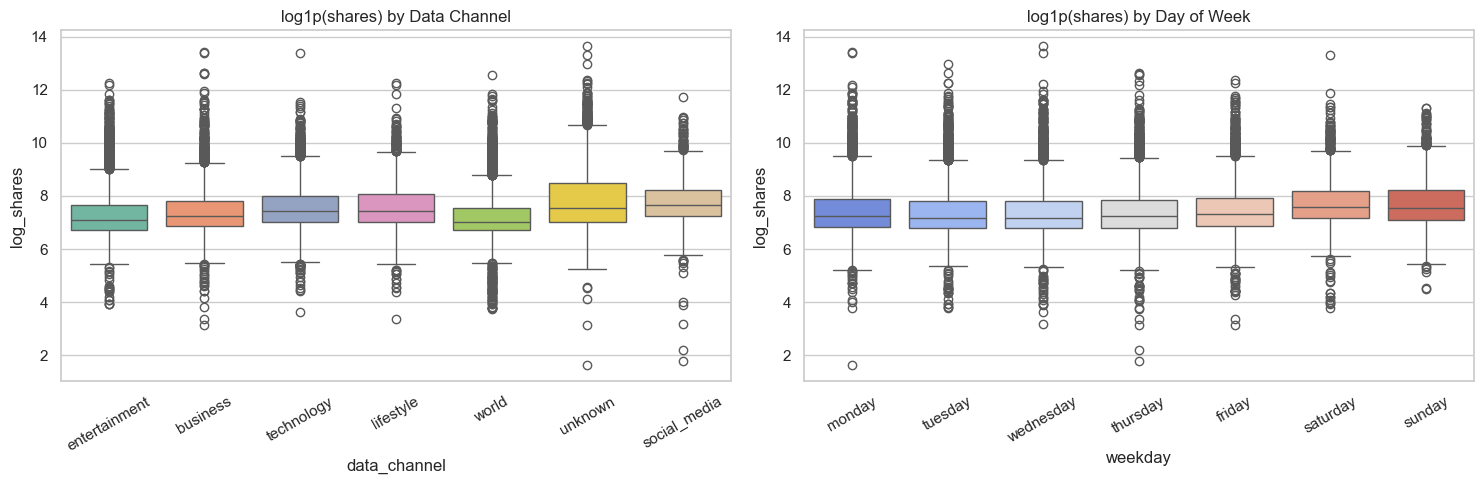

In [7]:
df_clean["log_shares"] = np.log1p(df_clean["shares"])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df_clean, x="data_channel", y="log_shares", ax=ax1, palette="Set2")
ax1.set_title("log1p(shares) by Data Channel")
ax1.tick_params(axis="x", rotation=30)

day_order = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]
sns.boxplot(data=df_clean, x="weekday", y="log_shares", order=day_order, ax=ax2, palette="coolwarm")
ax2.set_title("log1p(shares) by Day of Week")
ax2.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


## Correlation Analysis with log1p(shares) & VIF Check

In [8]:
numeric_eda = df_clean.drop(columns=["ID", "URL", "timedelta", "shares"], errors="ignore").select_dtypes(include=[np.number])
corr_target = numeric_eda.corr()["log_shares"].drop("log_shares").sort_values(ascending=False)
print("Top Positive & Negative Correlations with log1p(shares):")
display(pd.concat([corr_target.head(8), corr_target.tail(5)]))

vif_df = numeric_eda.drop(columns=["log_shares"]).replace([np.inf, -np.inf], np.nan)
vif_df = vif_df.fillna(vif_df.median()).fillna(0.0).astype(float)
vif_table = pd.DataFrame({
    "Feature": vif_df.columns,
    "VIF": [variance_inflation_factor(vif_df.values, i) for i in range(len(vif_df.columns))]
}).sort_values(by="VIF", ascending=False)
display(vif_table.head(12))


Top Positive & Negative Correlations with log1p(shares):


n_comments                  0.327218
kw_avg_avg                  0.219193
is_weekend                  0.116475
kw_min_avg                  0.108377
kw_max_avg                  0.106687
num_hrefs                   0.104387
total_media                 0.092373
num_imgs                    0.091115
n_tokens_title             -0.019921
n_non_stop_words           -0.031335
n_unique_tokens            -0.036106
average_token_length       -0.041884
n_non_stop_unique_tokens   -0.056506
Name: log_shares, dtype: float64

,Feature,VIF
22,kw_max_avg,292406.601387
26,kw_avg_range,243834.441058
21,kw_min_avg,10883.597886
24,total_media,2611.557913
7,num_imgs,2273.437093
3,n_non_stop_words,486.566611
10,average_token_length,327.744711
4,n_non_stop_unique_tokens,324.708904
8,num_videos,266.780402
2,n_unique_tokens,260.686121


## Model-Based Feature Importance Ranking (Random Forest Probe)

C:\Users\Ram\AppData\Local\Temp\ipykernel_29524\1525154492.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df.head(15), x="Importance", y="Feature", palette="viridis")


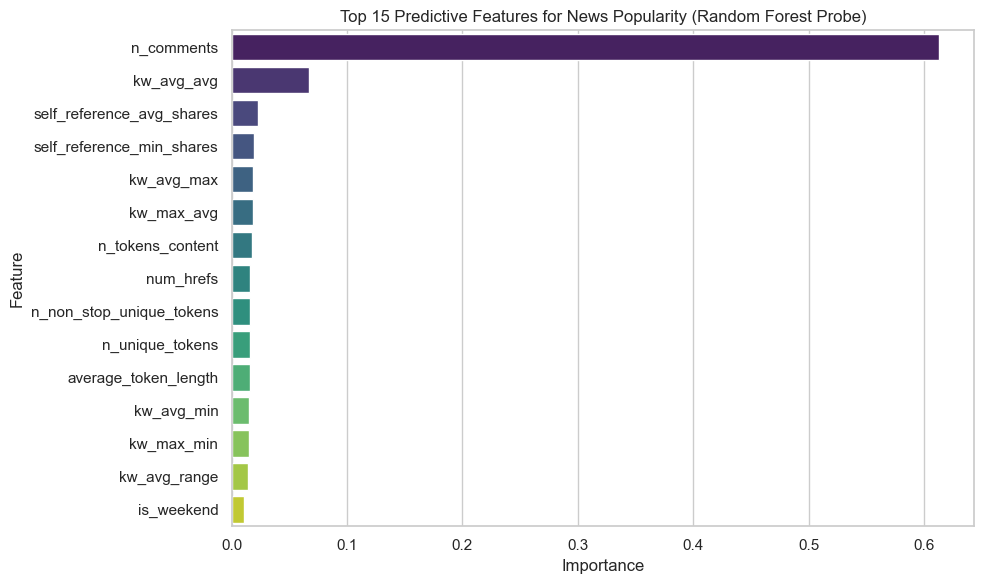

,Feature,Importance
9,n_comments,0.612742
23,kw_avg_avg,0.067218
13,self_reference_avg_shares,0.022911
11,self_reference_min_shares,0.019694
20,kw_avg_max,0.018991
22,kw_max_avg,0.018869
1,n_tokens_content,0.017437
5,num_hrefs,0.016435
4,n_non_stop_unique_tokens,0.016284
2,n_unique_tokens,0.016058


In [9]:
rf_df = pd.get_dummies(df_clean.drop(columns=["ID", "URL", "timedelta", "shares", "log_shares"], errors="ignore"), drop_first=True)
rf_df = rf_df.replace([np.inf, -np.inf], np.nan).fillna(rf_df.median()).fillna(0.0).astype(float)
y_rf = np.log1p(df_clean["shares"].values)

rf_probe = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_probe.fit(rf_df, y_rf)

imp_df = pd.DataFrame({"Feature": rf_df.columns, "Importance": rf_probe.feature_importances_}).sort_values(by="Importance", ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df.head(15), x="Importance", y="Feature", palette="viridis")
plt.title("Top 15 Predictive Features for News Popularity (Random Forest Probe)")
plt.tight_layout()
plt.show()
display(imp_df.head(15))
